In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle
from matplotlib.ticker import PercentFormatter
from PIL import Image, ImageOps

In [2]:
repo_dir = Path("../..")
osv5m_dir = repo_dir / "output/osv5m"
PARENT_LOG_DIR = osv5m_dir / "privacy_network"
network = PARENT_LOG_DIR / "osv5m_seed0"
seeds = [PARENT_LOG_DIR / "osv5m_seed0", PARENT_LOG_DIR / "osv5m_seed1", PARENT_LOG_DIR / "osv5m_seed2"]
geovit_dir = repo_dir / "output/geovit/privacy_network/geovit_seed0"
heat_dir = repo_dir / "data/heatmaps/osv5m/im2gps"
examples_dir = osv5m_dir / "examples"
poster_dir = repo_dir / "output/poster"
poster_dir.mkdir(exist_ok=True)

radius_km = 750
areas = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8]
judge_names = ["osv5m", "geovit", "geoclip"]
orange = "#eb6834"
aqua = "#1baf7a"
blue = "#2a78d6"
grey = "#8a8a85"
violet = "#6250d6"
yellow = "#eda100"
green = "#008300"
ink = "#0b0b0b"
muted = "#52514e"

base = pd.read_csv(osv5m_dir / "baseline_predictions.csv")
located_files = base.loc[base["km"] <= radius_km, "filename"]
full_seconds = float((osv5m_dir / "full_sigma20_seconds.txt").read_text())
heatmap_seconds = float((osv5m_dir / "heatmap_osv5m_seconds.txt").read_text())
heatmap_geovit_seconds = float((osv5m_dir / "heatmap_geovit_seconds.txt").read_text())
optimised_seconds = pd.read_csv(osv5m_dir / "optimised_a_star.csv")["seconds"].mean()

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
})

In [3]:
def load_heat(heat_dir, name):
    heat = np.load(heat_dir / f"{name}.npy").astype(np.float32)  # (448, 448)
    return heat.reshape(224, 2, 224, 2).mean(axis=(1, 3))  # (224, 224)

In [4]:
def load_mask(run_dir, name):
    return np.array(Image.open(run_dir / "best/im2gps/masks" / f"{name}.png")).astype(np.float32)  # (224, 224)

In [5]:
def load_photo(name):
    photo = Image.open(repo_dir / "data/im2gps" / f"{name}.jpg").convert("RGB")
    return ImageOps.fit(photo, (224, 224), Image.BICUBIC)  # (224, 224)

In [6]:
def display_scale(m, low_percentile):
    low = np.percentile(m, low_percentile)
    high = np.percentile(m, 99)
    return np.clip((m - low) / (high - low), 0, 1)

In [7]:
def overlap_ratio(reference, mask):
    return (mask * reference).sum() / mask.sum() / reference.mean()

In [8]:
def guess_km(csv_path, name):
    df = pd.read_csv(csv_path, dtype={"name": str})
    if "name" not in df.columns:
        df["name"] = df["filename"].str.replace(".jpg", "", regex=False)
    return df.loc[df["name"] == name, "km"].iloc[0]

In [9]:
def tint(color, strength):
    rgba = np.zeros((224, 224, 4))  # (224, 224, 4)
    rgba[..., :3] = to_rgb(color)
    rgba[..., 3] = 0.8 * strength
    return rgba

In [10]:
def frameless(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

In [11]:
def fmt(values, spec):
    if len(values) == 1:
        return format(values[0], spec)
    return f"{format(np.mean(values), spec)} ± {format(np.std(values, ddof=1), spec)}"

In [12]:
def blurred_area(method):
    quality = pd.read_csv(osv5m_dir / f"{method}_quality.csv").set_index("measure")["mean"]
    return quality["blurred_area"]

In [13]:
def baseline_hidden(method, judge_name):
    if judge_name == "osv5m":
        p = pd.read_csv(osv5m_dir / f"{method}_predictions.csv")
        return (p.loc[p["filename"].isin(located_files), "km"] > radius_km).mean()
    b = pd.read_csv(osv5m_dir / f"baselines_im2gps_{judge_name}.csv")
    return (b.loc[b["located"], method] > radius_km).mean()

In [14]:
def summary(run_dir, judge_name):
    return pd.read_csv(run_dir / "best/im2gps" / f"{judge_name}_summary.csv").iloc[0]

In [15]:
def n_located(judge_name):
    if judge_name == "osv5m":
        return len(located_files)
    return pd.read_csv(osv5m_dir / f"baselines_im2gps_{judge_name}.csv")["located"].sum()

In [16]:
unblurred = pd.read_csv(repo_dir / "data/osv5m/im2gps/unblurred_km_osv5m.csv", dtype={"name": str})
rows = []
for name in unblurred.loc[unblurred["km"] <= radius_km, "name"]:
    heat = load_heat(heat_dir, name)
    mask = load_mask(network, name)
    optimised = torch.load(osv5m_dir / "masks" / f"{name}.pt").float().numpy()[1, 0]  # (224, 224)
    rows.append(["heatmap vs network", overlap_ratio(heat, mask)])
    rows.append(["heatmap vs optimised 0.1", overlap_ratio(heat, optimised)])
    rows.append(["optimised 0.1 vs network", overlap_ratio(optimised, mask)])
    rows.append(["network seed 1 vs seed 0", overlap_ratio(load_mask(seeds[1], name), mask)])
    rows.append(["GeoViT network vs network", overlap_ratio(load_mask(geovit_dir, name), mask)])
    rows.append(["GeoViT heatmap vs GeoViT network", overlap_ratio(load_heat(repo_dir / "data/heatmaps/geovit/im2gps", name), load_mask(geovit_dir, name))])
ratios = pd.DataFrame(rows, columns=["pair", "ratio"]).groupby("pair", sort=False)["ratio"].mean()
ratios.to_csv(poster_dir / "overlap_ratio.csv")
ratios

pair
heatmap vs network                  1.207592
heatmap vs optimised 0.1            1.070643
optimised 0.1 vs network            1.144451
network seed 1 vs seed 0            1.307041
GeoViT network vs network           1.389265
GeoViT heatmap vs GeoViT network    1.171872
Name: ratio, dtype: float32

In [17]:
def plot_examples(names, area, save_path=None):
    titles = ["Original", "Full blur", f"Heatmap blur\n(hottest {area:.0%}\nfully blurred)", f"Optimized blur\n({area:.0%} area\ntarget)", "Privacy network\n(trained against\nOSV-5M)", "Privacy network\n(trained against\nGeoViT)"]
    fig, axes = plt.subplots(2 * len(names), 6, figsize=(12, 4.6 * len(names)), squeeze=False)
    for i, name in enumerate(names):
        original = load_photo(name)
        images = [
            original,
            Image.open(examples_dir / "full_sigma20" / f"{name}.png"),
            Image.open(examples_dir / f"heatmap_osv5m_{area}" / f"{name}.png"),
            Image.open(examples_dir / "optimised" / name / f"blurred_{area}.png"),
            Image.open(network / "best/im2gps/blurred" / f"{name}.png"),
            Image.open(geovit_dir / "best/im2gps/blurred" / f"{name}.png"),
        ]
        predictions = [
            osv5m_dir / "baseline_predictions.csv",
            osv5m_dir / "full_sigma20_predictions.csv",
            osv5m_dir / f"heatmap_osv5m_{area}_predictions.csv",
            osv5m_dir / f"optimised_{area}_predictions.csv",
            network / "best/im2gps/osv5m_predictions.csv",
            geovit_dir / "best/im2gps/osv5m_predictions.csv",
        ]
        heat = load_heat(heat_dir, name)
        q = max(np.quantile(heat, 1 - area), 1e-6)
        masks = [
            display_scale(heat, 50),
            np.ones((224, 224)),
            np.clip(heat / q, 0, 1),
            torch.load(osv5m_dir / "masks" / f"{name}.pt").float().numpy()[areas.index(area), 0],  # (224, 224)
            load_mask(network, name) / 255,
            load_mask(geovit_dir, name) / 255,
        ]
        grey_photo = np.array(original.convert("L"))  # (224, 224)

        for j in range(6):
            km = guess_km(predictions[j], name)
            if km > radius_km:
                status = "Hidden"
            else:
                status = "Found"
            axes[2 * i, j].imshow(images[j])
            axes[2 * i, j].set_xlabel(f"{status}: {km:,.0f} km", fontsize=12)
            axes[2 * i + 1, j].imshow(grey_photo, cmap="gray")
            if j == 0:
                axes[2 * i + 1, j].imshow(tint(orange, masks[j]))
            else:
                axes[2 * i + 1, j].imshow(tint(blue, masks[j]))
        axes[2 * i, 0].set_ylabel("Photo, guessed\nby OSV-5M")
        axes[2 * i + 1, 0].set_ylabel("Heatmap (orange),\nblur (blue)")

    for j in range(6):
        axes[0, j].set_title(titles[j], fontsize=12)
    for ax in axes.flat:
        frameless(ax)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

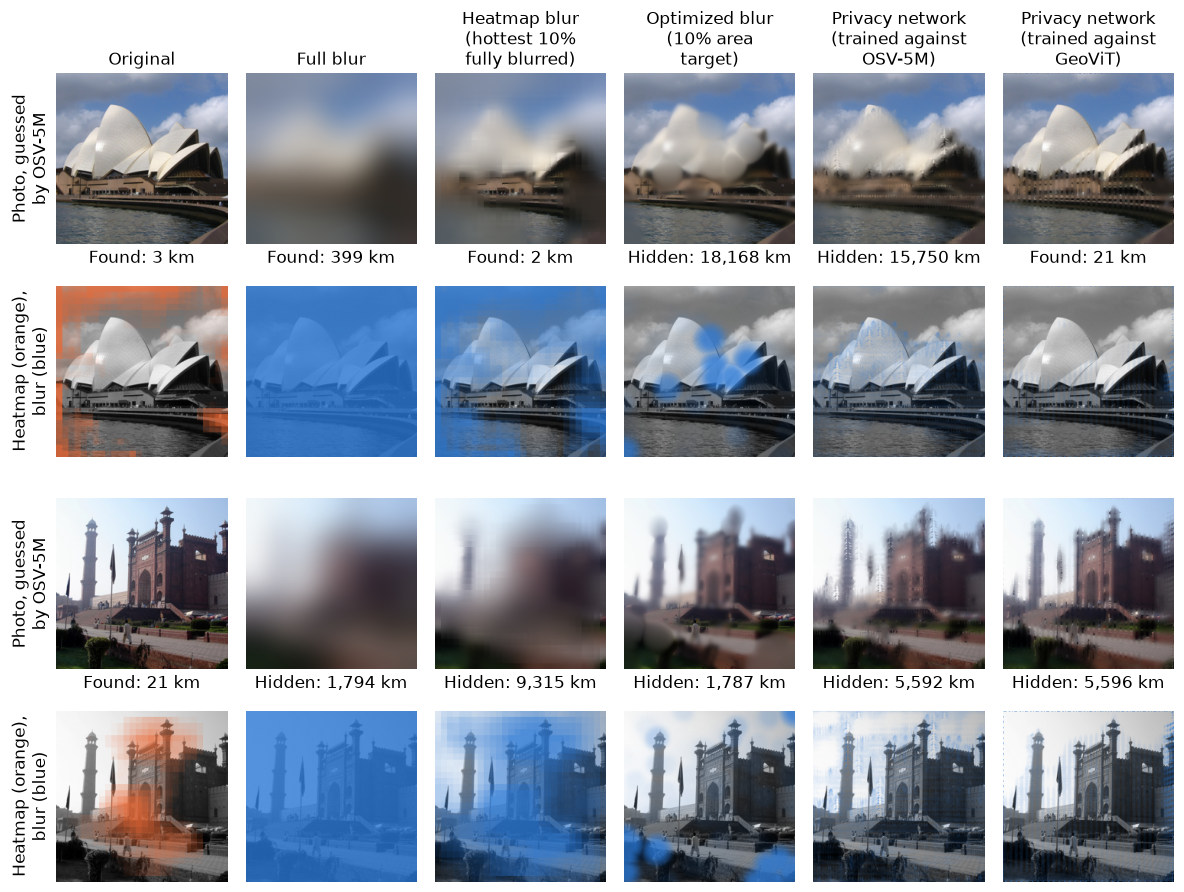

In [18]:
example_names = ["Sydney_00073_1226915900_eea86783cd_1128_65768710@N00", "Lahore_00001_321085080_28863df64f_130_82503882@N00"]
plot_examples(example_names, 0.1, save_path=poster_dir / "poster_examples.png")

In [19]:
def box(fig, x, y, w, h, text, color, edge=ink, fontsize=12):
    fig.add_artist(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.01", transform=fig.transFigure, facecolor=color, edgecolor=edge, linewidth=1.2))
    fig.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fontsize)

In [20]:
def arrow(fig, start, end, color=ink, dashed=False):
    linestyle = "-"
    if dashed:
        linestyle = "--"
    fig.add_artist(FancyArrowPatch(start, end, transform=fig.transFigure, arrowstyle="-|>", mutation_scale=14, color=color, linewidth=1.4, linestyle=linestyle))

In [21]:
def thumbnail(fig, x, y, image, title, subtitle, cmap=None):
    ax = fig.add_axes([x, y, 0.11, 0.30])
    ax.imshow(image, cmap=cmap, vmin=0, vmax=1)
    frameless(ax)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(subtitle, fontsize=11)

In [22]:
def plot_method(name, save_path=None):
    frozen_color = "#e6e5e0"
    trained_color = "#cde2fb"
    blurred = Image.open(network / "best/im2gps/blurred" / f"{name}.png")
    mask = display_scale(load_mask(network, name), 0)
    before = guess_km(osv5m_dir / "baseline_predictions.csv", name)
    after = guess_km(network / "best/im2gps/osv5m_predictions.csv", name)
    seconds = pd.read_csv(network / "best/im2gps/osv5m_summary.csv").iloc[0]["seconds"]

    fig = plt.figure(figsize=(13, 5.2))
    y = 0.735
    thumbnail(fig, 0.01, y - 0.15, load_photo(name), "Photo", f"OSV-5M: {before:,.0f} km off")
    fig.add_artist(FancyBboxPatch((0.165, y - 0.115), 0.31, 0.23, boxstyle="round,pad=0.005,rounding_size=0.01", transform=fig.transFigure, facecolor="none", edgecolor=muted, linewidth=1))
    fig.text(0.32, y + 0.125, "Privacy network", ha="center", va="bottom", fontsize=13, fontweight="bold")
    box(fig, 0.18, y - 0.085, 0.12, 0.17, "ViT encoder\n(frozen)", frozen_color)
    box(fig, 0.34, y - 0.085, 0.12, 0.17, "Conv decoder\n(trained)", trained_color, blue)
    thumbnail(fig, 0.505, y - 0.15, mask, "Blur mask m", "darker = more blur", "Blues")
    box(fig, 0.66, y - 0.085, 0.11, 0.17, "Blur each\npixel by m", frozen_color)
    thumbnail(fig, 0.81, y - 0.15, blurred, "Protected photo", f"OSV-5M: {after:,.0f} km off")
    arrow(fig, (0.12, y), (0.18, y))
    arrow(fig, (0.3, y), (0.34, y))
    arrow(fig, (0.46, y), (0.505, y))
    arrow(fig, (0.615, y), (0.66, y))
    arrow(fig, (0.77, y), (0.81, y))
    fig.add_artist(Line2D([0.145], [y], transform=fig.transFigure, marker="o", markersize=5, color=ink))
    fig.add_artist(Line2D([0.145, 0.145, 0.715], [y, 0.96, 0.96], transform=fig.transFigure, color=ink, linewidth=1.4))
    arrow(fig, (0.715, 0.96), (0.715, y + 0.085))

    box(fig, 0.01, 0.27, 0.03, 0.06, "", frozen_color)
    fig.text(0.05, 0.3, "frozen or fixed", va="center", fontsize=11)
    box(fig, 0.01, 0.17, 0.03, 0.06, "", trained_color, blue)
    fig.text(0.05, 0.2, "trained", va="center", fontsize=11)
    fig.text(0.01, 0.07, f"Protecting a photo:\none pass, {seconds:.3f} s", va="center", fontsize=11)

    fig.add_artist(Rectangle((0.27, 0.03), 0.72, 0.38, transform=fig.transFigure, facecolor="none", edgecolor=muted, linewidth=1, linestyle="--"))
    fig.text(0.28, 0.375, "Training only", ha="left", va="center", fontsize=12, fontweight="bold", color=muted)
    box(fig, 0.79, 0.1, 0.15, 0.17, "Geolocator\n(frozen OSV-5M)", frozen_color)
    loss_text = r"loss = log $P_{near}$ + $\lambda_{area}$ mean(m) + $\lambda_{tv}$ smoothness(m)" + "\n" + r"$P_{near}$ = probability of the cells within 750 km of the truth"
    box(fig, 0.3, 0.08, 0.44, 0.21, loss_text, "#fcfcfb", fontsize=11)
    arrow(fig, (0.865, 0.545), (0.865, 0.27))
    arrow(fig, (0.79, 0.185), (0.74, 0.185))
    arrow(fig, (0.4, 0.29), (0.4, y - 0.085), blue, dashed=True)
    fig.text(0.41, 0.47, "update the decoder only", ha="left", va="center", fontsize=10, color=blue)

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

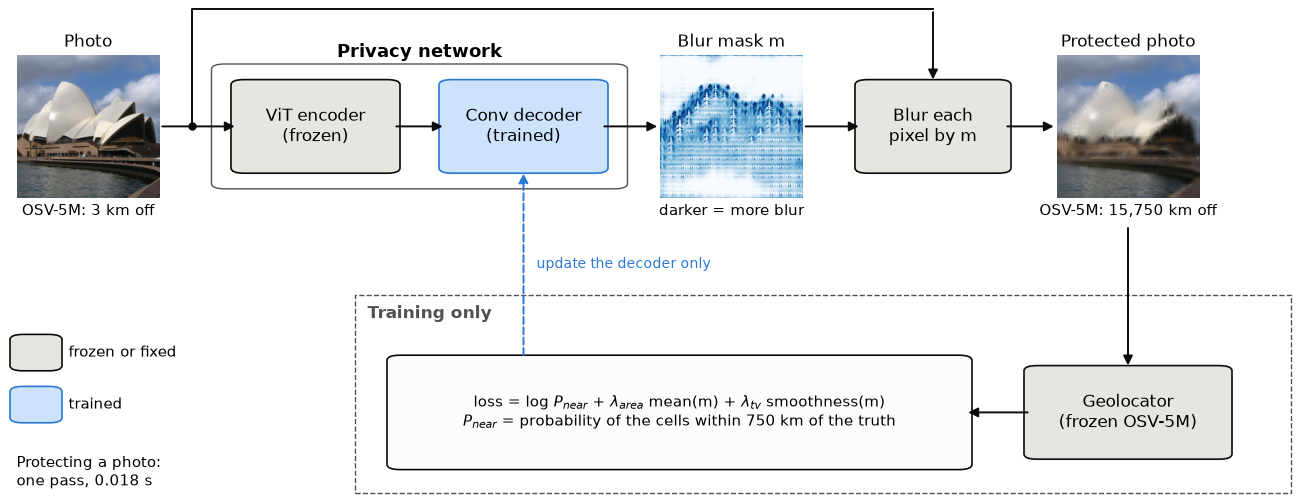

In [23]:
plot_method("Sydney_00073_1226915900_eea86783cd_1128_65768710@N00", save_path=poster_dir / "poster_method.png")

In [24]:
def baseline_point(method, judge_name):
    p = pd.read_csv(osv5m_dir / f"{method}_predictions.csv")
    return p["lpips"].mean(), baseline_hidden(method, judge_name)

In [25]:
def label_time(ax, seconds, hidden):
    if seconds >= 10:
        text = f"{seconds:.0f} s"
    elif seconds >= 1:
        text = f"{seconds:.1f} s"
    elif seconds >= 0.1:
        text = f"{seconds:.2f} s"
    elif seconds >= 0.001:
        text = f"{seconds:.3f} s"
    else:
        text = f"{seconds:.4f} s"
    ax.annotate(text, (seconds, hidden), xytext=(0, -14), textcoords="offset points", ha="center", fontsize=10, color=muted)

In [26]:
def plot_tradeoff(judge_name, judge_label, lines, network_runs, save_path=None):
    fig, (ax, ax_time) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
    for method, color, label, seconds in lines:
        x = []
        y = []
        for a in areas:
            lpips, hidden = baseline_point(f"{method}_{a}", judge_name)
            x.append(lpips)
            y.append(hidden)
        ax.plot(x, y, "o-", color=color, label=label)
        ax_time.plot([seconds] * len(y), y, "o-", color=color)
        label_time(ax_time, seconds, min(y))

    x = []
    y = []
    seconds = []
    for i, (run_dir, label) in enumerate(network_runs.items()):
        s = summary(run_dir, judge_name)
        x.append(s["lpips"])
        y.append(s["hidden"])
        seconds.append(s["seconds"])
        if i == 0 or i == len(network_runs) - 1:
            ax.annotate(label, (s["lpips"], s["hidden"]), xytext=(6, -10), textcoords="offset points", fontsize=10, color=muted)
    ax.plot(x, y, "o-", color=blue, label="Privacy network")
    ax_time.plot([np.median(seconds)] * len(y), y, "o-", color=blue)
    label_time(ax_time, np.median(seconds), min(y))

    lpips, hidden = baseline_point("full_sigma20", judge_name)
    ax.plot(lpips, hidden, "s", color=grey, label="Full blur")
    ax_time.plot(full_seconds, hidden, "s", color=grey)
    label_time(ax_time, full_seconds, hidden)
    ax.plot(0, 0, "D", color=grey, label="No blur")

    ax.set_xlim(-0.02, 0.9)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("Image damage (LPIPS, lower is better)")
    ax.set_ylabel(f"Hidden from {judge_label}\n(% of the {n_located(judge_name)} photos it locates)")
    ax.set_title("Privacy against image damage", loc="left")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc="lower right", frameon=False)

    ax_time.set_xscale("log")
    ax_time.set_xlim(1e-5, 3e3)
    ax_time.set_xlabel("Seconds per photo on an RTX 5070 (log scale, lower is better)")
    ax_time.set_title("Privacy against speed", loc="left")

    for a in [ax, ax_time]:
        a.grid(color="#e6e5e0")
        a.set_axisbelow(True)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

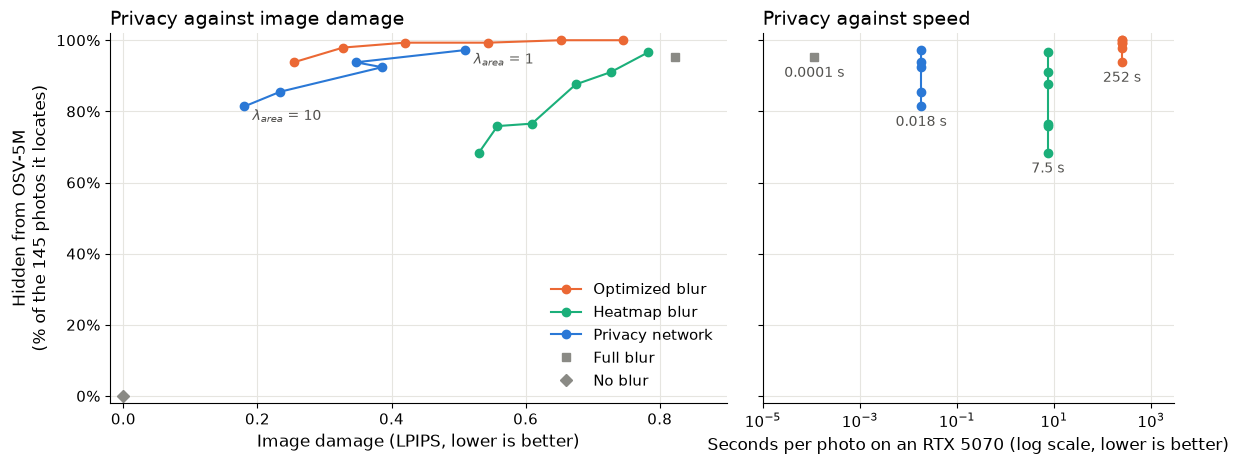

In [27]:
lines = [
    ["optimised", orange, "Optimized blur", optimised_seconds],
    ["heatmap_osv5m", aqua, "Heatmap blur", heatmap_seconds],
]
network_runs = {
    PARENT_LOG_DIR / "area1_seed0": r"$\lambda_{area}$ = 1",
    PARENT_LOG_DIR / "area2_seed0": r"$\lambda_{area}$ = 2",
    PARENT_LOG_DIR / "osv5m_seed0": r"$\lambda_{area}$ = 3",
    PARENT_LOG_DIR / "area7_seed0": r"$\lambda_{area}$ = 7",
    PARENT_LOG_DIR / "area10_seed0": r"$\lambda_{area}$ = 10",
}
plot_tradeoff("osv5m", "OSV-5M", lines, network_runs, save_path=poster_dir / "poster_tradeoff_osv5m.png")

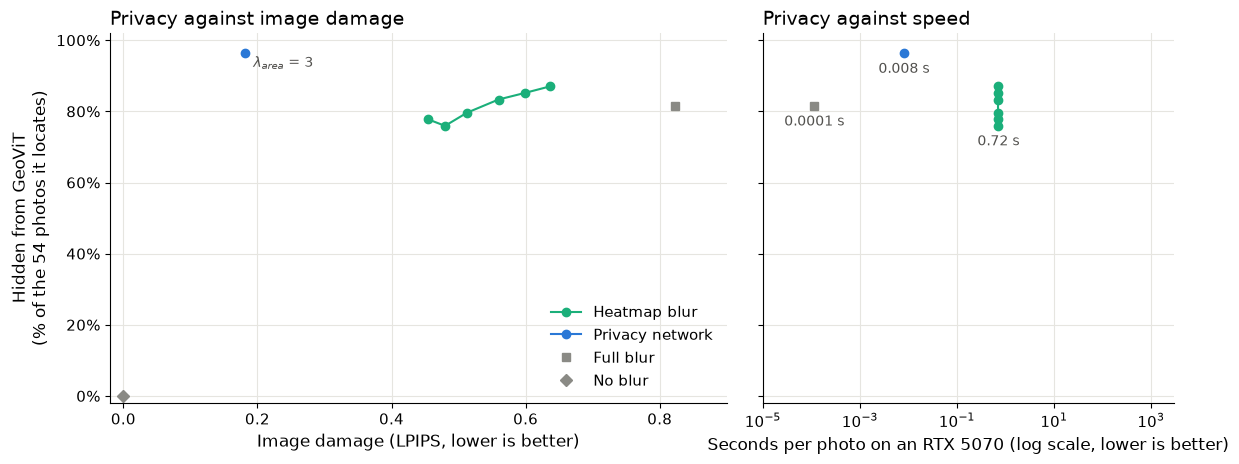

In [28]:
lines = [["heatmap_geovit", aqua, "Heatmap blur", heatmap_geovit_seconds]]
plot_tradeoff("geovit", "GeoViT", lines, {geovit_dir: r"$\lambda_{area}$ = 3"}, save_path=poster_dir / "poster_tradeoff_geovit.png")

In [29]:
def draw_table(table, bold, shaded, save_path):
    fig, ax = plt.subplots(figsize=(12, 0.45 * (len(table) + 1)))
    ax.axis("off")
    t = ax.table(cellText=table.values, colLabels=list(table.columns), loc="center", cellLoc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(12)
    t.auto_set_column_width(list(range(len(table.columns))))
    for (r, c), cell in t.get_celld().items():
        if r == 0:
            cell.set_height(cell.get_height() * 2.6)
            cell.set_text_props(fontweight="bold")
        else:
            cell.set_height(cell.get_height() * 1.5)
        if r in shaded:
            cell.set_facecolor("#eaf2fc")
        cell.set_edgecolor(cell.get_facecolor())
    for r, c in bold:
        t[(r, c)].set_text_props(fontweight="bold")

    fig.canvas.draw()
    last_column = t[(0, len(table.columns) - 1)]
    left = t[(0, 0)].get_x()
    right = last_column.get_x() + last_column.get_width()
    header = t[(0, 0)]
    for y in [header.get_y() + header.get_height(), header.get_y(), t[(len(table), 0)].get_y()]:
        ax.plot([left, right], [y, y], color=muted, linewidth=1.2, transform=ax.transAxes, clip_on=False)
    plt.savefig(save_path, bbox_inches="tight")
    plt.show()

In [30]:
def baseline_row(label, method, area, seconds, judge_name="osv5m"):
    p = pd.read_csv(osv5m_dir / f"{method}_predictions.csv")
    return [label, format(area, ".0%"), format(baseline_hidden(method, judge_name), ".0%"), format(p["lpips"].mean(), ".2f"), format(p["ssim"].mean(), ".2f"), seconds]

In [31]:
def network_row(label, run_dirs, judge_name="osv5m"):
    area = []
    hidden = []
    lpips = []
    ssim = []
    for run_dir in run_dirs:
        s = summary(run_dir, judge_name)
        area.append(s["area"])
        hidden.append(s["hidden"])
        lpips.append(s["lpips"])
        ssim.append(s["ssim"])
    return [label, fmt(area, ".0%"), fmt(hidden, ".0%"), fmt(lpips, ".2f"), fmt(ssim, ".2f"), f"{s['seconds']:.3f} s"]

In [32]:
def baseline_transfer(method):
    hidden = []
    for judge_name in judge_names:
        hidden.append(baseline_hidden(method, judge_name))
    return hidden

In [33]:
def network_transfer(run_dir):
    hidden = []
    for judge_name in judge_names:
        hidden.append(summary(run_dir, judge_name)["hidden"])
    return hidden

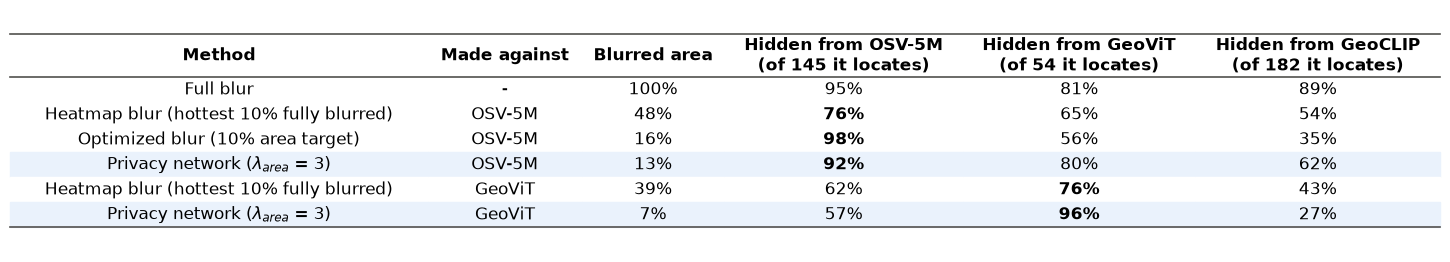

,Method,Made against,Blurred area,Hidden from OSV-5M\n(of 145 it locates),Hidden from GeoViT\n(of 54 it locates),Hidden from GeoCLIP\n(of 182 it locates)
0,Full blur,-,100%,95%,81%,89%
1,Heatmap blur (hottest 10% fully blurred),OSV-5M,48%,76%,65%,54%
2,Optimized blur (10% area target),OSV-5M,16%,98%,56%,35%
3,Privacy network ($\lambda_{area}$ = 3),OSV-5M,13%,92%,80%,62%
4,Heatmap blur (hottest 10% fully blurred),GeoViT,39%,62%,76%,43%
5,Privacy network ($\lambda_{area}$ = 3),GeoViT,7%,57%,96%,27%


In [34]:
transfer = [
    ["Full blur", "-", 1.0, baseline_transfer("full_sigma20")],
    ["Heatmap blur (hottest 10% fully blurred)", "OSV-5M", blurred_area("heatmap_osv5m_0.1"), baseline_transfer("heatmap_osv5m_0.1")],
    ["Optimized blur (10% area target)", "OSV-5M", blurred_area("optimised_0.1"), baseline_transfer("optimised_0.1")],
    [r"Privacy network ($\lambda_{area}$ = 3)", "OSV-5M", summary(network, "osv5m")["area"], network_transfer(network)],
    ["Heatmap blur (hottest 10% fully blurred)", "GeoViT", blurred_area("heatmap_geovit_0.1"), baseline_transfer("heatmap_geovit_0.1")],
    [r"Privacy network ($\lambda_{area}$ = 3)", "GeoViT", summary(geovit_dir, "osv5m")["area"], network_transfer(geovit_dir)],
]
rows = []
for label, made_against, area, hidden in transfer:
    row = [label, made_against, format(area, ".0%")]
    for h in hidden:
        row.append(format(h, ".0%"))
    rows.append(row)
columns = ["Method", "Made against", "Blurred area"]
for judge_label, judge_name in zip(["OSV-5M", "GeoViT", "GeoCLIP"], judge_names):
    columns.append(f"Hidden from {judge_label}\n(of {n_located(judge_name)} it locates)")
table3 = pd.DataFrame(rows, columns=columns)
table3.to_csv(poster_dir / "poster_table_transfer.csv", index=False)
draw_table(table3, [(2, 3), (3, 3), (4, 3), (5, 4), (6, 4)], [4, 6], poster_dir / "poster_table_transfer.png")
table3

In [35]:
def plot_transfer(transfer, save_path=None):
    judge_labels = ["OSV-5M", "GeoViT", "GeoCLIP"]
    judge_colors = [violet, yellow, green]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ticks = []
    tick_labels = []
    for i, (label, made_against, area, hidden) in enumerate(transfer):
        y = len(transfer) - 1 - i
        ax.plot([min(hidden), max(hidden)], [y, y], color="#e6e5e0", linewidth=8, solid_capstyle="round", zorder=1)
        for j in range(3):
            if i == 0:
                ax.scatter(hidden[j], y, s=110, color=judge_colors[j], zorder=2, label=f"Guessed by {judge_labels[j]}")
            else:
                ax.scatter(hidden[j], y, s=110, color=judge_colors[j], zorder=2)
        if made_against == "-":
            made_against = "no model"
        ticks.append(y)
        tick_labels.append(f"{label.split(' (')[0]}\nmade against {made_against}, {area:.0%} blurred")
    ax.set_yticks(ticks, tick_labels)
    ax.set_xlim(0.2, 1.02)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Hidden from each model (% of the photos it locates)")
    ax.set_title("Does a blur fool models it was not made for?", loc="left")
    ax.grid(axis="x", color="#e6e5e0")
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

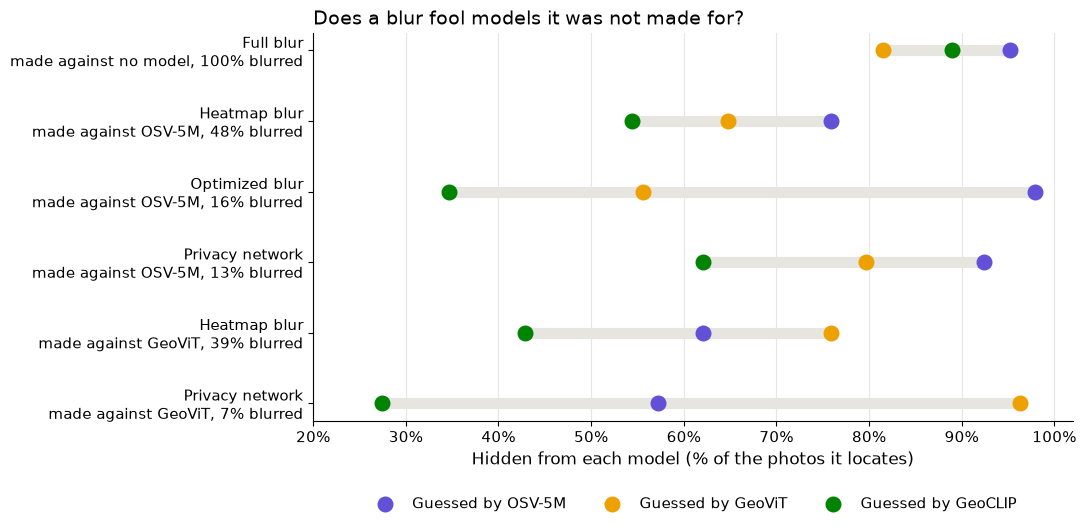

In [36]:
plot_transfer(transfer, save_path=poster_dir / "poster_plot_transfer.png")

In [37]:
def robustness(judge_name, method):
    c = pd.read_csv(osv5m_dir / f"compression_im2gps_{judge_name}.csv")
    hidden = []
    for condition in ["png", "jpeg", "screenshot"]:
        hidden.append(c.loc[(c["method"] == method) & (c["condition"] == condition), "hidden"].iloc[0])
    return hidden

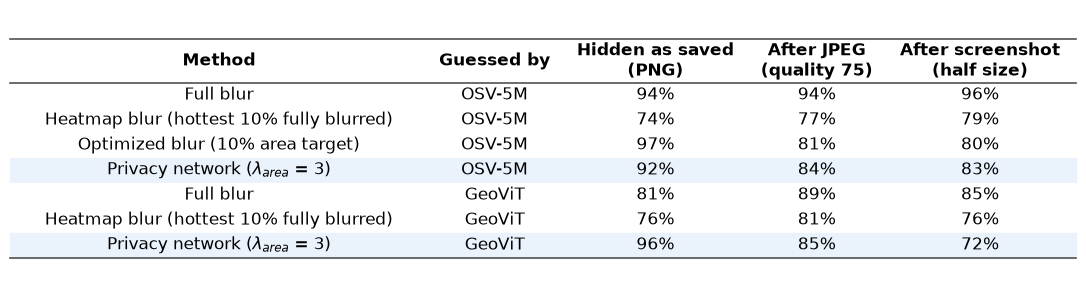

,Method,Guessed by,Hidden as saved\n(PNG),After JPEG\n(quality 75),After screenshot\n(half size)
0,Full blur,OSV-5M,94%,94%,96%
1,Heatmap blur (hottest 10% fully blurred),OSV-5M,74%,77%,79%
2,Optimized blur (10% area target),OSV-5M,97%,81%,80%
3,Privacy network ($\lambda_{area}$ = 3),OSV-5M,92%,84%,83%
4,Full blur,GeoViT,81%,89%,85%
5,Heatmap blur (hottest 10% fully blurred),GeoViT,76%,81%,76%
6,Privacy network ($\lambda_{area}$ = 3),GeoViT,96%,85%,72%


In [38]:
labels = {
    "full_sigma20": "Full blur",
    "heatmap_osv5m_0.1": "Heatmap blur (hottest 10% fully blurred)",
    "heatmap_geovit_0.1": "Heatmap blur (hottest 10% fully blurred)",
    "optimised_0.1": "Optimized blur (10% area target)",
    "network": r"Privacy network ($\lambda_{area}$ = 3)",
}
judge_methods = {
    "OSV-5M": ["osv5m", ["full_sigma20", "heatmap_osv5m_0.1", "optimised_0.1", "network"]],
    "GeoViT": ["geovit", ["full_sigma20", "heatmap_geovit_0.1", "network"]],
}
rows = []
for judge_label, (judge_name, methods) in judge_methods.items():
    for method in methods:
        row = [labels[method], judge_label]
        for h in robustness(judge_name, method):
            row.append(format(h, ".0%"))
        rows.append(row)
columns = ["Method", "Guessed by", "Hidden as saved\n(PNG)", "After JPEG\n(quality 75)", "After screenshot\n(half size)"]
table4 = pd.DataFrame(rows, columns=columns)
table4.to_csv(poster_dir / "poster_table_robustness.csv", index=False)
draw_table(table4, [], [4, 7], poster_dir / "poster_table_robustness.png")
table4

In [39]:
def plot_robustness(save_path=None):
    condition_labels = ["As saved\n(PNG)", "JPEG\n(quality 75)", "Screenshot\n(half size)"]
    method_colors = {"full_sigma20": grey, "heatmap_osv5m_0.1": aqua, "heatmap_geovit_0.1": aqua, "optimised_0.1": orange, "network": blue}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for ax, (judge_label, (judge_name, methods)) in zip(axes, judge_methods.items()):
        for method in methods:
            ax.plot(range(3), robustness(judge_name, method), "o-", color=method_colors[method], linewidth=2, markersize=8, label=labels[method].split(" (")[0])
        ax.set_xticks(range(3), condition_labels)
        ax.set_xlim(-0.2, 2.2)
        ax.set_title(f"Guessed by {judge_label} ({n_located(judge_name)} photos)", loc="left")
        ax.grid(axis="y", color="#e6e5e0")
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Hidden (% of the photos\nthe model locates)")
    axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axes[0].set_ylim(0.6, 1.0)
    axes[0].legend(loc="lower left", frameon=False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

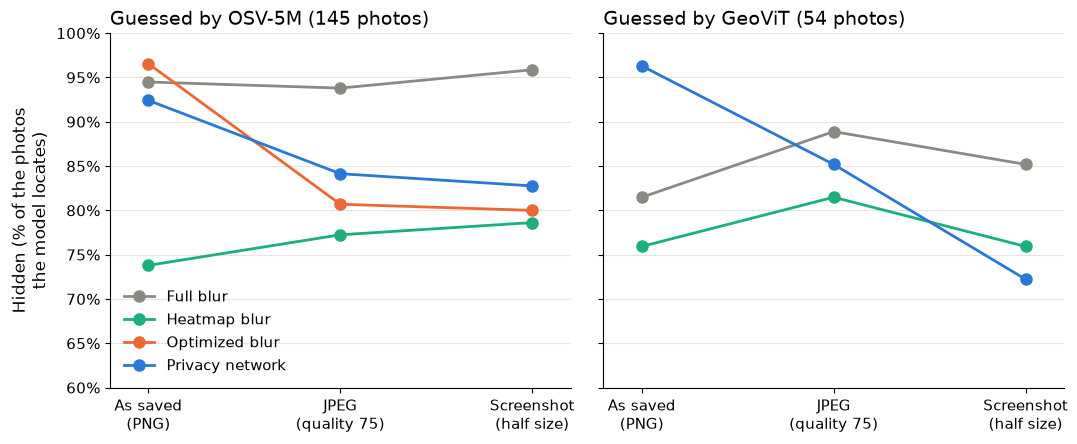

In [40]:
plot_robustness(save_path=poster_dir / "poster_plot_robustness.png")